<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1: K-Means Clustering — Customer Segmentation
Objective: Build a K-Means clustering model to segment customers based on their Annual Income and Spending Score.

Dataset: Task-Datasets/task1_kmeans_customer_data.csv

Features to use for clustering: Annual_Income, Spending_Score

Instructions:

Import the necessary libraries (pandas, numpy, matplotlib, sklearn)
Load the dataset and explore its structure (.head(), .info(), .describe())
Extract the feature columns: Annual_Income and Spending_Score
Apply the Elbow Method to determine the optimal number of clusters:
Test K values from 1 to 10
Calculate WCSS (Within-Cluster Sum of Squares) for each K
Use KMeans(n_clusters=i, init='k-means++', n_init=10, max_iter=300, random_state=0)
Plot K values vs. WCSS and identify the "elbow"
Build the final K-Means model using the optimal K value
Predict cluster labels using .fit_predict()
Visualize the clusters with different colors for each cluster and mark the centroids in yellow
Deliverables:

Elbow Method plot (K vs. WCSS)
Final cluster visualization with centroids
Brief interpretation: What does each cluster represent in terms of customer behavior?

In [ ]:
#importing the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#importing the datasets
data = pd.read_csv('/content/drive/MyDrive/task1_kmeans_customer_data.csv')
data.head(20)

,Customer_ID,Gender,Age,Annual_Income,Spending_Score
0,1,Female,40,17.5,22.3
1,2,Female,26,14.3,13.9
2,3,Male,29,18.2,15.3
3,4,Female,18,22.6,7.9
4,5,Male,18,13.8,12.3
5,6,Male,64,13.8,15.6
6,7,Male,51,22.9,9.2
7,8,Female,49,18.8,16.9
8,9,Female,42,12.7,12.0
9,10,Male,57,17.7,13.5


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Customer_ID     100 non-null    int64  
 1   Gender          100 non-null    object 
 2   Age             100 non-null    int64  
 3   Annual_Income   100 non-null    float64
 4   Spending_Score  100 non-null    float64
dtypes: float64(2), int64(2), object(1)
memory usage: 4.0+ KB


In [ ]:
data.describe()

,Customer_ID,Age,Annual_Income,Spending_Score
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,40.400000,53.228000,49.513000
std,29.011492,13.626326,32.792399,30.051211
min,1.000000,18.000000,10.000000,5.200000
25%,25.750000,29.000000,18.500000,21.725000
50%,50.500000,43.000000,53.950000,49.700000
75%,75.250000,51.000000,83.625000,78.725000
max,100.000000,64.000000,111.800000,92.500000


In [ ]:
#selecting the Annual_Income and Spending_Score columns  as the X
X= data.iloc[:, [3,4]].values

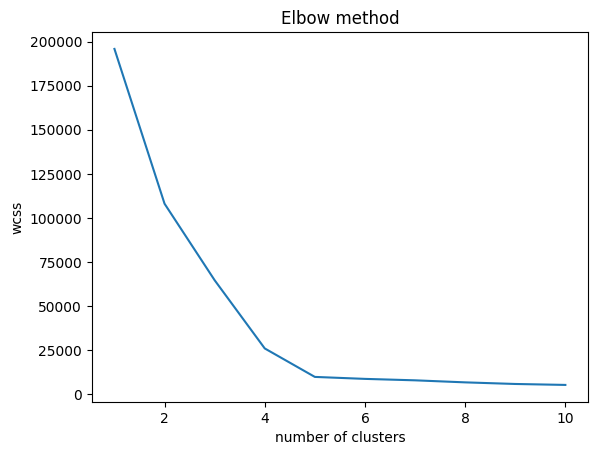

In [ ]:
#Apply the Elbow Method to determine the optimal number of clusters
from sklearn.cluster import KMeans
wcss = []
#creating the for loop using the range of (1, 11) as it is the possible values of k this means we are testing 1 to 10 as the value of k
for i in range(1,11):
  kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, max_iter=300, random_state=0)
  kmeans.fit(X)
  wcss.append(kmeans.inertia_)
plt.plot(range(1,11), wcss)
plt.title('Elbow method')
plt.xlabel('number of clusters')
plt.ylabel('wcss')
plt.show()

### Observation

The Elbow Method indicates that the optimal number of clusters is 5. There is a sharp decrease in WCSS from K=1 to K=5, after which the curve begins to flatten. This suggests that additional clusters beyond 5 provide minimal improvement in reducing within-cluster variance.

In [ ]:
#Build the final K-Means model using the optimal K value Predict cluster labels using .fit_predict() Visualize the clusters with different colors for each cluster and mark the centroids in yellow Deliverables:
kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, max_iter=300, random_state=0)
Y_kmeans = kmeans.fit_predict(X)

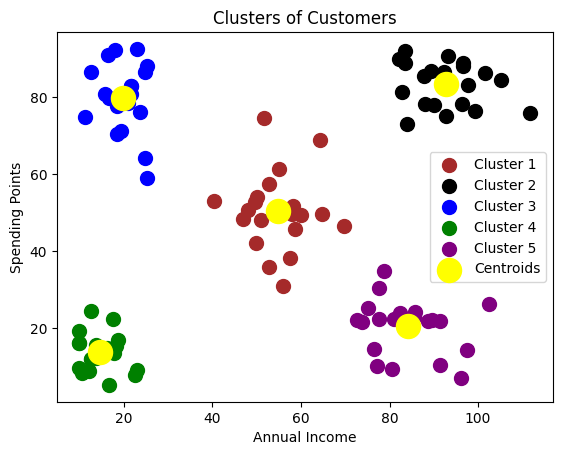

In [ ]:
# Visualising the clusters
plt.scatter(X[Y_kmeans==0, 0], X[Y_kmeans==0, 1], s=100, c='brown', label= 'Cluster 1')
plt.scatter(X[Y_kmeans==1, 0], X[Y_kmeans==1, 1], s=100, c='black', label= 'Cluster 2')
plt.scatter(X[Y_kmeans==2, 0], X[Y_kmeans==2, 1], s=100, c='blue', label= 'Cluster 3')
plt.scatter(X[Y_kmeans==3, 0], X[Y_kmeans==3, 1], s=100, c='green', label= 'Cluster 4')
plt.scatter(X[Y_kmeans==4, 0], X[Y_kmeans==4, 1], s=100, c='purple', label= 'Cluster 5')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroids' )
plt.title('Clusters of Customers')
plt.xlabel('Annual Income')
plt.ylabel('Spending Points')
plt.legend()
plt.show()

**Cluster 1 (brown)** represents customers with medium annual income and moderate spending scores. These customers exhibit balanced purchasing behavior and likely form the mainstream customer base. They are neither highly conservative nor excessively high spenders. This segment represents stable and consistent buyers who can be retained through loyalty programs, regular engagement, and personalized recommendations.

**Cluster 2 (black)** consists of customers with high annual income and high spending scores. These are premium or high-value customers who contribute significantly to business revenue. They have strong purchasing power and actively spend, making them ideal targets for exclusive offers, VIP memberships, and premium product lines. Retaining this segment is critical for maximizing profitability.

**Cluster 3 (blue)** represents customers with low annual income but high spending scores. Despite having limited income, these customers demonstrate relatively high purchasing behavior. They may include younger consumers or impulse buyers who allocate a larger portion of their income to shopping. Marketing strategies such as trend-based promotions and loyalty rewards may effectively engage this group.

**Cluster 4 (green)** consists of customers with low annual income and low spending scores. This segment is likely highly price-sensitive and cautious in their purchasing behavior. Their spending is limited, possibly focused on essential items. Businesses targeting this group should emphasize affordability, discounts, and value-for-money products to increase engagement.

**Cluster 5 (purple)** represents customers with high annual income but low spending scores. Although they have strong purchasing power, they currently spend conservatively. This group presents a growth opportunity, as targeted marketing, personalized campaigns, and premium positioning strategies could encourage increased spending and stronger brand engagement.

Hierarchical Clustering — Plant Species Grouping
Objective: Apply Hierarchical (Agglomerative) Clustering to group plant samples based on physical measurements.

Dataset: Task-Datasets/task2_hierarchical_plant_data.csv

Features to use for clustering: Sepal_Length, Sepal_Width, Petal_Length, Petal_Width

Instructions:

Import the necessary libraries (pandas, numpy, matplotlib, scipy, sklearn)
Load the dataset and explore its structure
Extract the four feature columns (all columns except Sample_ID)
Create a Dendrogram to visualize the hierarchical structure:
Use scipy.cluster.hierarchy.dendrogram() and scipy.cluster.hierarchy.linkage()
Use the ward linkage method
Label the axes: "Samples" (x-axis) and "Euclidean Distances" (y-axis)
Identify the optimal number of clusters from the dendrogram
Fit Agglomerative Clustering to the dataset:
Use AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
Predict cluster labels using .fit_predict()
Visualize the clusters using a scatter plot (use Petal_Length vs. Petal_Width as axes)
Deliverables:

Dendrogram visualization
Scatter plot of clusters with different colors
Brief explanation of how you determined the number of clusters from the dendrogram

In [ ]:
#importing the necessary dataset
df = pd.read_csv('/content/drive/MyDrive/task2_hierarchical_plant_data.csv')
df.head(10)


,Sample_ID,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width
0,1,5.08,3.57,1.20,0.29
1,2,4.73,3.52,1.60,0.42
2,3,4.89,3.65,1.67,0.32
3,4,4.84,2.98,1.69,0.45
4,5,5.26,3.64,1.37,0.14
5,6,4.88,3.36,1.56,0.48
6,7,5.15,3.46,1.50,0.24
7,8,5.60,3.28,1.64,0.19
8,9,5.38,3.90,1.59,0.30
9,10,4.87,2.79,1.52,0.18


In [ ]:
#Extract the four feature columns (all columns except Sample_ID)
x = df.iloc[:, [1,4]].values


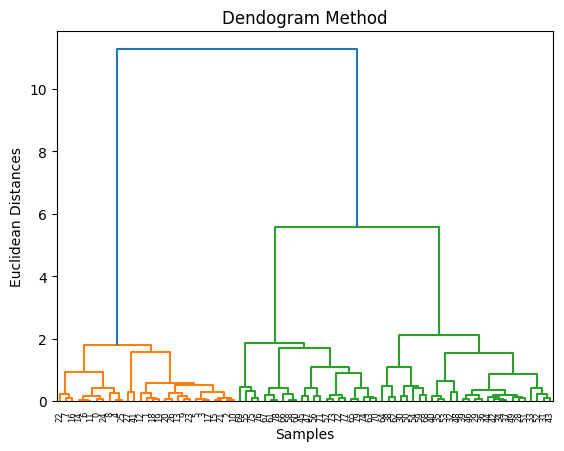

In [ ]:
# creating the Dendogram Method
#Create a Dendrogram to visualize the hierarchical structure: Use scipy.cluster.hierarchy.dendrogram() and scipy.cluster.hierarchy.linkage() Use the ward linkage method Label the axes: "Samples" (x-axis) and "Euclidean Distances" (y-axis)
import scipy.cluster.hierarchy as sch
den_gram = sch.dendrogram(sch.linkage(x, method='ward'))
plt.title('Dendogram Method')
plt.xlabel('Samples')
plt.ylabel('Euclidean Distances')
plt.savefig('img_1.png', dpi=500)
plt.show()

 to Identify the optimal number of clusters from the dendrogram
Looking at the two long vertical blue lines at the top. imagining drawing a horizontal line through that wide gap (roughly at the height of 8 on the Y-axis), you would only intersect 2 vertical lines.
While the orange and green sections show further sub-groupings, the jump in "Euclidean Distance" (the Y-axis) is much smaller for those. The massive gap between the top merge and the next set of merges suggests that the data naturally splits into two primary, distinct super-groups.
### the optimal number of clusters is 2.

In [ ]:
# Fitting Hierarchical Cluster Analysis to dataset
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(x)
print(y_hc)


[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 2 0 2 0 0 0 0 0 0 0 2 2 2 2 0 2 2 0 2 0 2 2 2 0 2 2 2 2 2
 2 2 2 2 2 2]


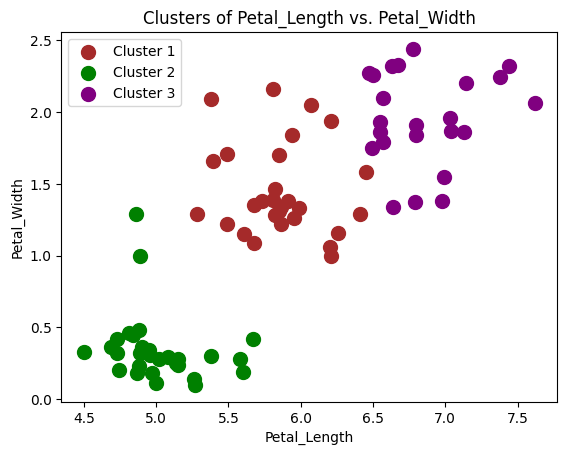

In [ ]:
# Visualising the clusters
plt.scatter(x[y_hc==0, 0], x[y_hc==0, 1], s=100, c='brown', label= 'Cluster 1')
plt.scatter(x[y_hc==1, 0], x[y_hc==1, 1], s=100, c='green', label= 'Cluster 2')
plt.scatter(x[y_hc==2, 0], x[y_hc==2, 1], s=100, c='purple', label= 'Cluster 3')
plt.title('Clusters of Petal_Length vs. Petal_Width')
plt.xlabel('Petal_Length')
plt.ylabel('Petal_Width')
plt.legend()
plt.show()

**Cluster 2 (Green)**: This is the most distinct group. It is completely isolated in the bottom-left corner, representing flowers with small petals. This matches the orange "branch" on the far left of the dendrogram that stays separate from everything else until the very last merge.

**Clusters 1 (Brown) and 3 (Purple)**: These two groups are closer together, reflecting the green "branches" on the right of the dendrogram. While they are separate, there is a slight overlap or proximity between them, suggesting they share more similarities with each other than they do with the Green group.

**Model Accuracy**: The clear separation of the Green cluster suggests the model is very confident in identifying that specific species, whereas the boundary between brown and Purple is where the "unsupervised" nature of the model is doing the most work to find a distinction.

 NLP Text Preprocessing Pipeline
Objective: Apply the full NLP preprocessing pipeline to a collection of text samples using NLTK.

Dataset: Task-Datasets/task3_nlp_text_data.csv

Instructions:

Import the necessary libraries (pandas, nltk)

Download required NLTK resources:

import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('maxent_ne_chunker')
nltk.download('words')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')
Load the dataset and select any 5 text samples of your choice

For each of the 5 selected texts, perform and display the results of:

a) Tokenization

Apply sentence tokenization using sent_tokenize()
Apply word tokenization using word_tokenize()
Display both results
b) Stemming

Apply Porter Stemmer (PorterStemmer) to the word-tokenized text
Display original words alongside their stemmed versions
c) Lemmatization

Apply WordNet Lemmatizer (WordNetLemmatizer) to the word-tokenized text
Display original words alongside their lemmatized versions
d) Stop Word Removal

Remove English stop words from the tokenized text using stopwords.words('english')
Display the filtered word list (without stop words)
e) POS Tagging

Apply Part-of-Speech tagging using pos_tag() on the tokenized words
Display the tagged words with their POS labels
f) Named Entity Recognition (NER)

Apply NER using ne_chunk() on the POS-tagged words
Identify and list any named entities (persons, organizations, locations, etc.)
Deliverables:

Complete preprocessing output for all 5 selected texts
A summary table comparing the word count before and after stop word removal for each text
Identify which texts contain named entities and list them


In [ ]:
#importing the necessary libraries
# Tokenization
import nltk
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('maxent_ne_chunker')
nltk.download('words')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker.zip.
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading packag

True

In [ ]:
#importing the dataset
dataset = pd.read_csv("/content/drive/MyDrive/task3_nlp_text_data.csv")

# Displaying first few rows
print(dataset.head())

   Text_ID                                               Text
0        1  The quick brown fox jumps over the lazy dog in...
1        2  I absolutely LOVED this movie! It was fantasti...
2        3  The weather today is beautiful, perfect for a ...
3        4  Python programming is incredibly useful for da...
4        5  She was running quickly through the streets, l...


In [ ]:
# Picking a single text sample
text = dataset['Text'].iloc[2]


In [ ]:
#applying Tokenizing sentences
print(sent_tokenize(text=text, language='english'))
for i in sent_tokenize(text=text, language='english'):
    print(i)

['The weather today is beautiful, perfect for a morning walk.']
The weather today is beautiful, perfect for a morning walk.


In [ ]:
#Apply word tokenization using word_tokenize()
words = word_tokenize(text)
print(words)

['The', 'weather', 'today', 'is', 'beautiful', ',', 'perfect', 'for', 'a', 'morning', 'walk', '.']


In [ ]:
#stemming/lemmatization
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in words]

print("Stemmed:", stemmed_words)
print("Lemmatized:", lemmatized_words)

Stemmed: ['the', 'weather', 'today', 'is', 'beauti', ',', 'perfect', 'for', 'a', 'morn', 'walk', '.']
Lemmatized: ['The', 'weather', 'today', 'is', 'beautiful', ',', 'perfect', 'for', 'a', 'morning', 'walk', '.']


In [ ]:
#Stop Word Removal
from nltk.corpus import stopwords

# Initialize stop words
stop_words = set(stopwords.words('english'))

# Filtering the stop words
filtered_words = [word for word in words if word.lower() not in stop_words]

# Displaying the result
print("Original Words: ", words)
print("Without Stop Words: ", filtered_words)

Original Words:  ['The', 'weather', 'today', 'is', 'beautiful', ',', 'perfect', 'for', 'a', 'morning', 'walk', '.']
Without Stop Words:  ['weather', 'today', 'beautiful', ',', 'perfect', 'morning', 'walk', '.']


In [ ]:
# Selecting 5 text samples
sample_texts = dataset['Text'].head(5)

In [ ]:
# Preparing summary data
summary_data = []


In [ ]:
# Processing each text
from nltk import pos_tag, ne_chunk
for i, text in enumerate(sample_texts, 1):
    print("\n" + "="*60)
    print(f"TEXT {i}: {text}\n")

    # Word tokenization
    words = word_tokenize(text)

    # POS tagging
    pos_tags = pos_tag(words)
    print("POS Tagging (Word → POS):")
    for word, tag in pos_tags:
        print(f"{word:15} → {tag}")

    # Named Entity Recognition (NER)
    ner_tree = ne_chunk(pos_tags)

    # Extracting named entities
    named_entities = []
    for subtree in ner_tree:
        if hasattr(subtree, 'label'):
            entity = " ".join([leaf[0] for leaf in subtree.leaves()])
            named_entities.append((entity, subtree.label()))

    print("\nNamed Entities Found:")
    print(named_entities if named_entities else "None")



TEXT 1: The quick brown fox jumps over the lazy dog in the garden.

POS Tagging (Word → POS):
The             → DT
quick           → JJ
brown           → NN
fox             → NN
jumps           → VBZ
over            → IN
the             → DT
lazy            → JJ
dog             → NN
in              → IN
the             → DT
garden          → NN
.               → .

Named Entities Found:
None

TEXT 2: I absolutely LOVED this movie! It was fantastic and amazing.

POS Tagging (Word → POS):
I               → PRP
absolutely      → RB
LOVED           → VBP
this            → DT
movie           → NN
!               → .
It              → PRP
was             → VBD
fantastic       → JJ
and             → CC
amazing         → JJ
.               → .

Named Entities Found:
None

TEXT 3: The weather today is beautiful, perfect for a morning walk.

POS Tagging (Word → POS):
The             → DT
weather         → NN
today           → NN
is              → VBZ
beautiful       → JJ
,               → ,
per

In [ ]:
# Updating the summary
summary_data.append({
        'Text Index': i,
        'Original Word Count': len(words),
        'Word Count after Stop Word Removal': len(filtered_words),
        'Named Entities': named_entities if named_entities else "None"
    })

# Create summary table
summary_df = pd.DataFrame(summary_data)

print("\nSummary Table (Word Counts and Named Entities):")
print(summary_df)


Summary Table (Word Counts and Named Entities):
   Text Index  Original Word Count  Word Count after Stop Word Removal  \
0           5                   14                                   8   

  Named Entities  
0           None  


Assignments: https://colab.research.google.com/drive/15N72Ez6aRFhPpr1IrtSybGAt_clVgpEZ?usp=sharing

Assessments: https://colab.research.google.com/drive/1HAYgh4W8CmFNTzflVhIiIdocFHpUWMJ3?usp=sharing

Write up:https://medium.com/@jacinta.chege213/week-19-customer-segmentation-and-feedback-insights-from-clustering-to-dimensionality-reduction-84977beaf3bf